# 04 · Modelo de regresión logística: probabilidad de defunción por dengue

Entrada: `datos-procesados/dengue_limpio.csv` (generado en `02_limpieza.ipynb`, explorado en `03_EDA.ipynb`).

Objetivo: estimar $P(\text{DEFUNCION}=1 \mid X)$ con una regresión logística

$$\log\frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$$

e interpretar $e^{\beta_j}$ como la **razón de momios (OR) ajustada** de cada predictor.

**Decisiones que vienen del EDA**

| Hallazgo del EDA | Decisión en este notebook |
|---|---|
| Solo 0.70% de defunciones (≈ 1:142) | Partición estratificada; evaluar con AUC-ROC, AUC-PR, Brier y calibración, no con exactitud; umbral elegido explícitamente |
| La edad **no** es lineal en el logit (forma de U/J) | Comparar edad lineal, cuadrática y spline; usar la mejor |
| `HOSPITALIZADO` es probablemente consecuencia de la gravedad | Ajustar **dos modelos**: A (sin hospitalización, factores del paciente) y B (con hospitalización) |
| Mes con efecto débil e IC traslapados | Probar el bloque de meses con razón de verosimilitud antes de incluirlo |
| Pocos eventos en inmunosupresión, cirrosis y DENV4 | Revisar convergencia e IC; se mantienen si el modelo converge |
| VIF máximo ≈ 5.2 | Sin colinealidad grave; se usan todas las dummies |

| Sección | Contenido |
|---|---|
| 1 · Datos y partición | Variables, centrado de la edad, entrenamiento / prueba |
| 2 · Especificación | Forma de la edad, meses y serotipo (pruebas de razón de verosimilitud) |
| 3 · Modelo A | Sin hospitalización: OR ajustadas |
| 4 · Modelo B | Con hospitalización: OR ajustadas y comparación con A |
| 5 · Efecto de la edad | Probabilidad predicha por edad |
| 6 · Desempeño | ROC, precisión-sensibilidad y Brier en el conjunto de prueba |
| 7 · Calibración | Hosmer-Lemeshow y curva de calibración |
| 8 · Umbral | Sensibilidad, especificidad y matriz de confusión |
| 9 · Interacciones | Análisis de sensibilidad |
| 10 · Conclusiones | |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from patsy import build_design_matrices
from scipy import stats
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 50)
DATA = Path("datos-procesados")
SEMILLA = 42

# Misma paleta que 03_EDA (validada para daltonismo): azul = modelo A / sobrevivió, naranja = modelo B / defunción
AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, GRIS = "#0b0b0b", "#52514e", "#d9d8d4"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "text.color": TINTA, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "figure.dpi": 110, "font.size": 10, "legend.frameon": False,
})
SECUENCIAL = LinearSegmentedColormap.from_list("azul", ["#f0efec", "#86b6ef", "#2a78d6", "#0d366b"])
pct = mticker.PercentFormatter(1, decimals=1)

dengue = pd.read_csv(DATA / "dengue_limpio.csv")
print(f"{dengue.shape[0]:,} filas × {dengue.shape[1]} columnas | defunciones: {dengue.DEFUNCION.sum():,} ({dengue.DEFUNCION.mean():.2%})")

251,900 filas × 29 columnas | defunciones: 1,763 (0.70%)


## 1 · Datos y partición

- **Edad centrada y escalada:** `EDAD10 = (edad − 30) / 10`. Con esto el intercepto corresponde a una persona de 30 años, el coeficiente lineal se lee "por cada 10 años" y el término cuadrático `EDAD10²` no queda casi colineal con el lineal.
- **Referencias de las dummies:** serotipo DENV1 y mes octubre (como en el EDA).
- **Partición 70 / 30 estratificada** por `DEFUNCION`: el modelo se especifica y se estima **solo** con entrenamiento; el conjunto de prueba se usa al final para medir el desempeño con datos que el modelo no vio.
- **No se rebalancean las clases** (sin sobremuestreo ni pesos). Rebalancear sesga las probabilidades predichas hacia arriba; como el objetivo es estimar la *probabilidad* de muerte, se conserva la prevalencia real y el desbalance se maneja con el umbral (sección 8).

In [2]:
COMORBILIDADES = ["DIABETES", "HIPERTENSION", "ENFERMEDAD_RENAL", "INMUNOSUPR", "CIRROSIS_HEPATICA", "EMBARAZO"]
DEMOGRAFICAS = ["HOMBRE", "COSTERA", "INDIGENA"]
CLINICAS = ["HEMORRAGICOS"]
SEROTIPOS = ["DENV2", "DENV3", "DENV4", "SIN_SEROTIPO"]            # referencia: DENV1
MESES = [c for c in dengue.columns if c.startswith("MES_")]        # referencia: MES_OCT
EDAD = ["EDAD10", "EDAD10_2"]

dengue["EDAD10"] = (dengue.EDAD_ANOS - 30) / 10
dengue["EDAD10_2"] = dengue.EDAD10 ** 2

entrena, prueba = train_test_split(dengue, test_size=0.30, stratify=dengue.DEFUNCION, random_state=SEMILLA)

pd.DataFrame({
    "casos": [len(entrena), len(prueba)],
    "defunciones": [entrena.DEFUNCION.sum(), prueba.DEFUNCION.sum()],
    "mortalidad": [entrena.DEFUNCION.mean(), prueba.DEFUNCION.mean()],
}, index=["entrenamiento", "prueba"]).style.format({"casos": "{:,}", "defunciones": "{:,}", "mortalidad": "{:.3%}"})

,casos,defunciones,mortalidad
entrenamiento,"176,330","1,234",0.700%
prueba,"75,570",529,0.700%


## 2 · Especificación del modelo

Todas las comparaciones se hacen en **entrenamiento**. Para modelos anidados se usa la **prueba de razón de verosimilitud** (LR): $LR = 2(\ell_1 - \ell_0) \sim \chi^2_{gl}$; para no anidados, el **AIC** (menor es mejor).

Base de comparación: demográficas + hemorrágicos + comorbilidades + serotipo (sin hospitalización).

In [3]:
def formula(*bloques):
    return "DEFUNCION ~ " + " + ".join(v for b in bloques for v in b)

def ajustar(f, datos=entrena):
    m = smf.logit(f, datos).fit(disp=0, maxiter=200)
    assert m.mle_retvals["converged"], f"No convergió: {f}"
    return m

def prueba_lr(m0, m1):
    lr = 2 * (m1.llf - m0.llf)
    gl = int(m1.df_model - m0.df_model)
    return lr, gl, stats.chi2.sf(lr, gl)

BASE = [DEMOGRAFICAS, CLINICAS, COMORBILIDADES, SEROTIPOS]

formas_edad = {
    "Lineal":            ["EDAD10"],
    "Cuadrática":        EDAD,
    "Spline natural (4 gl)": ["cr(EDAD_ANOS, df=4)"],
}
modelos_edad = {k: ajustar(formula(*BASE, v)) for k, v in formas_edad.items()}
tabla_edad = pd.DataFrame({
    "parámetros de edad": [m.df_model - modelos_edad["Lineal"].df_model + 1 for m in modelos_edad.values()],
    "log-verosimilitud": [m.llf for m in modelos_edad.values()],
    "AIC": [m.aic for m in modelos_edad.values()],
}, index=modelos_edad.keys())
tabla_edad["ΔAIC vs. lineal"] = tabla_edad.AIC - tabla_edad.AIC["Lineal"]
lr, gl, p = prueba_lr(modelos_edad["Lineal"], modelos_edad["Cuadrática"])
print(f"Lineal vs. cuadrática: LR = {lr:.1f}, gl = {gl}, p = {p:.1e}\n")
tabla_edad.round(1)

Lineal vs. cuadrática: LR = 188.2, gl = 1, p = 7.8e-43



,parámetros de edad,log-verosimilitud,AIC,ΔAIC vs. lineal
Lineal,1.0,-6959.6,13951.3,0.0
Cuadrática,2.0,-6865.5,13765.1,-186.2
Spline natural (4 gl),3.0,-6866.1,13768.1,-183.1


In [4]:
m_sin_meses = modelos_edad["Cuadrática"]
m_con_meses = ajustar(formula(*BASE, EDAD, MESES))
m_sin_sero = ajustar(formula(DEMOGRAFICAS, CLINICAS, COMORBILIDADES, EDAD))

bloques = []
for nombre, m0, m1 in [("Mes (11 dummies)", m_sin_meses, m_con_meses),
                       ("Serotipo (4 dummies)", m_sin_sero, m_sin_meses)]:
    lr, gl, p = prueba_lr(m0, m1)
    bloques.append({"bloque": nombre, "LR": lr, "gl": gl, "p": p, "AIC sin": m0.aic, "AIC con": m1.aic})
pd.DataFrame(bloques).set_index("bloque").style.format({"LR": "{:.1f}", "p": "{:.4f}", "AIC sin": "{:,.1f}", "AIC con": "{:,.1f}"})

,LR,gl,p,AIC sin,AIC con
bloque,,,,,
Mes (11 dummies),16.0,11,0.1422,"13,765.1","13,771.1"
Serotipo (4 dummies),18.9,4,0.0008,"13,776.0","13,765.1"


**Decisión de especificación**

- **Edad cuadrática.** Mejora mucho a la lineal (ΔAIC ≈ −180, LR p < 1e-40) y el spline de 4 grados de libertad no la supera, así que se prefiere la forma más simple de interpretar.
- **Sin meses.** El bloque de 11 dummies no es significativo y *empeora* el AIC: la estacionalidad afecta cuántos casos hay, pero no la letalidad una vez ajustado por lo demás.
- **Con serotipo.** El bloque es significativo, aunque recuérdese que está confundido con la época de captura (notebook 02).

## 3 · Modelo A: factores del paciente (sin hospitalización)

Responde a: *dadas las características del paciente al enfermar, ¿cuál es su riesgo de morir?* Es el modelo útil para **identificar factores de riesgo**, porque no incluye variables que son consecuencia de la gravedad.

In [5]:
VARIABLES_A = DEMOGRAFICAS + CLINICAS + COMORBILIDADES + SEROTIPOS + EDAD
modelo_a = ajustar(formula(VARIABLES_A))

def tabla_or(m):
    ic = np.exp(m.conf_int())
    t = pd.DataFrame({"β": m.params, "EE": m.bse, "OR": np.exp(m.params),
                      "IC 2.5%": ic[0], "IC 97.5%": ic[1], "p": m.pvalues}).drop(index="Intercept")
    return t

def formato_or(t):
    return t.style.format({"β": "{:.3f}", "EE": "{:.3f}", "OR": "{:.2f}", "IC 2.5%": "{:.2f}",
                           "IC 97.5%": "{:.2f}", "p": "{:.1e}"}) \
                  .apply(lambda fila: ["font-weight: bold" if fila.p < 0.05 else "color: #8a8986"] * len(fila), axis=1)

print(f"Modelo A — n = {int(modelo_a.nobs):,}, pseudo-R² de McFadden = {modelo_a.prsquared:.3f}, "
      f"LR vs. modelo nulo = {modelo_a.llr:,.0f} (p = {modelo_a.llr_pvalue:.0e}), AIC = {modelo_a.aic:,.0f}")
formato_or(tabla_or(modelo_a))

Modelo A — n = 176,330, pseudo-R² de McFadden = 0.066, LR vs. modelo nulo = 975 (p = 3e-197), AIC = 13,765


,β,EE,OR,IC 2.5%,IC 97.5%,p
HOMBRE,0.070,0.059,1.07,0.96,1.20,2.3e-01
COSTERA,0.299,0.069,1.35,1.18,1.54,1.3e-05
INDIGENA,0.085,0.156,1.09,0.80,1.48,5.8e-01
HEMORRAGICOS,0.924,0.152,2.52,1.87,3.39,1.2e-09
DIABETES,0.761,0.108,2.14,1.73,2.65,1.9e-12
HIPERTENSION,0.424,0.119,1.53,1.21,1.93,3.7e-04
ENFERMEDAD_RENAL,1.747,0.172,5.74,4.10,8.03,2.8e-24
INMUNOSUPR,0.909,0.341,2.48,1.27,4.84,7.6e-03
CIRROSIS_HEPATICA,1.466,0.404,4.33,1.96,9.57,2.9e-04
EMBARAZO,0.632,0.170,1.88,1.35,2.62,1.9e-04


**Cómo leer la tabla.** OR > 1: el factor aumenta los momios de morir manteniendo constantes las demás variables. En negritas, p < 0.05. Para la edad, los coeficientes `EDAD10` y `EDAD10²` no se interpretan por separado; su efecto conjunto se ve en la sección 5.

## 4 · Modelo B: con hospitalización

Agrega `HOSPITALIZADO`. Es el modelo más útil para **predecir** el desenlace de un paciente que ya llegó a una unidad de salud, pero sus OR de las comorbilidades se interpretan como *efecto adicional al de haber sido hospitalizado*.

In [6]:
VARIABLES_B = VARIABLES_A + ["HOSPITALIZADO"]
modelo_b = ajustar(formula(VARIABLES_B))
lr, gl, p = prueba_lr(modelo_a, modelo_b)

print(f"Modelo B — pseudo-R² de McFadden = {modelo_b.prsquared:.3f}, AIC = {modelo_b.aic:,.0f}")
print(f"LR al agregar HOSPITALIZADO: {lr:,.0f} (gl = {gl}, p = {p:.0e}) | ΔAIC = {modelo_b.aic - modelo_a.aic:,.0f}")
formato_or(tabla_or(modelo_b))

Modelo B — pseudo-R² de McFadden = 0.173, AIC = 12,198
LR al agregar HOSPITALIZADO: 1,569 (gl = 1, p = 0e+00) | ΔAIC = -1,567


,β,EE,OR,IC 2.5%,IC 97.5%,p
HOMBRE,0.059,0.059,1.06,0.94,1.19,3.2e-01
COSTERA,0.067,0.069,1.07,0.93,1.23,3.3e-01
INDIGENA,0.259,0.157,1.30,0.95,1.76,9.9e-02
HEMORRAGICOS,0.702,0.149,2.02,1.51,2.70,2.4e-06
DIABETES,0.481,0.104,1.62,1.32,1.98,4.0e-06
HIPERTENSION,0.169,0.116,1.18,0.94,1.49,1.5e-01
ENFERMEDAD_RENAL,1.373,0.169,3.95,2.84,5.49,3.8e-16
INMUNOSUPR,0.716,0.330,2.05,1.07,3.91,3.0e-02
CIRROSIS_HEPATICA,1.170,0.390,3.22,1.50,6.92,2.7e-03
EMBARAZO,-0.046,0.170,0.96,0.68,1.33,7.9e-01


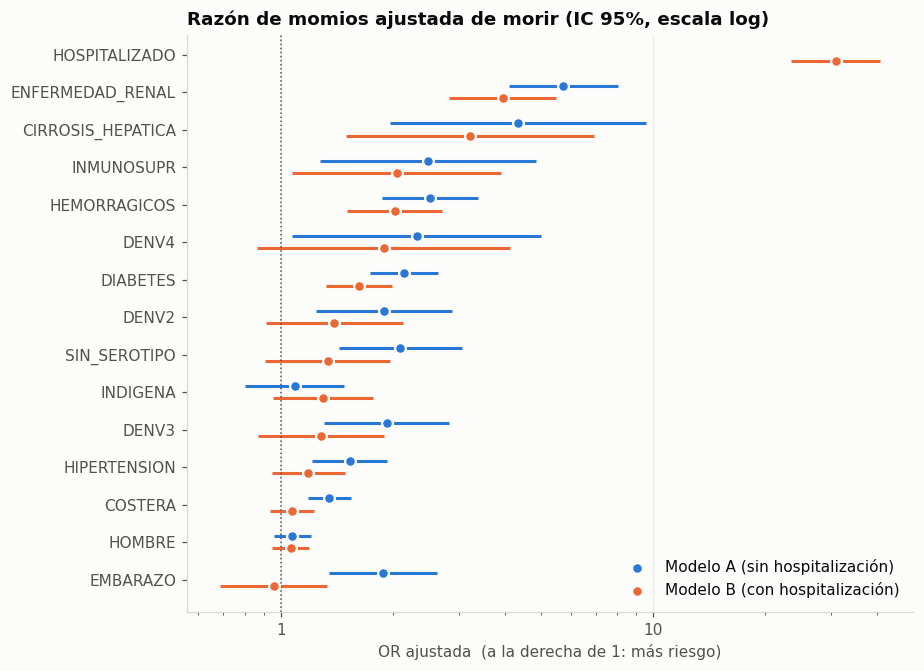

In [7]:
or_a, or_b = tabla_or(modelo_a), tabla_or(modelo_b)
orden = [v for v in or_b.drop(index=EDAD).sort_values("OR").index]

fig, ax = plt.subplots(figsize=(8.5, 6.2))
y = np.arange(len(orden))
for t, desplaza, color, etiqueta in [(or_a, 0.17, AZUL, "Modelo A (sin hospitalización)"),
                                     (or_b, -0.17, NARANJA, "Modelo B (con hospitalización)")]:
    t = t.reindex(orden)
    ok = t.OR.notna()
    ax.hlines(y[ok] + desplaza, t["IC 2.5%"][ok], t["IC 97.5%"][ok], color=color, linewidth=2)
    ax.scatter(t.OR[ok], y[ok] + desplaza, color=color, s=50, zorder=3, edgecolor="#fcfcfb", linewidth=1.5, label=etiqueta)
ax.axvline(1, color=TINTA_2, linewidth=1, linestyle=":")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_yticks(y, orden)
ax.grid(axis="y", visible=False)
ax.set(title="Razón de momios ajustada de morir (IC 95%, escala log)", xlabel="OR ajustada  (a la derecha de 1: más riesgo)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Comparación A vs. B.** Al agregar la hospitalización, casi todas las OR se **acercan a 1**: parte del efecto de las comorbilidades y del serotipo opera *a través* de que el paciente se agrava y se hospitaliza. Las variables que conservan su efecto en B son factores de riesgo con efecto adicional aun entre pacientes con el mismo tipo de atención.

## 5 · Efecto de la edad

Como la edad entra con término cuadrático, su efecto se muestra como la **probabilidad predicha** a lo largo de la edad para un perfil de referencia: mujer, no costera, no indígena, sin hemorragia ni comorbilidades, sin serotipo identificado (la categoría más común). La banda es el IC 95% (método delta en la escala del logit).

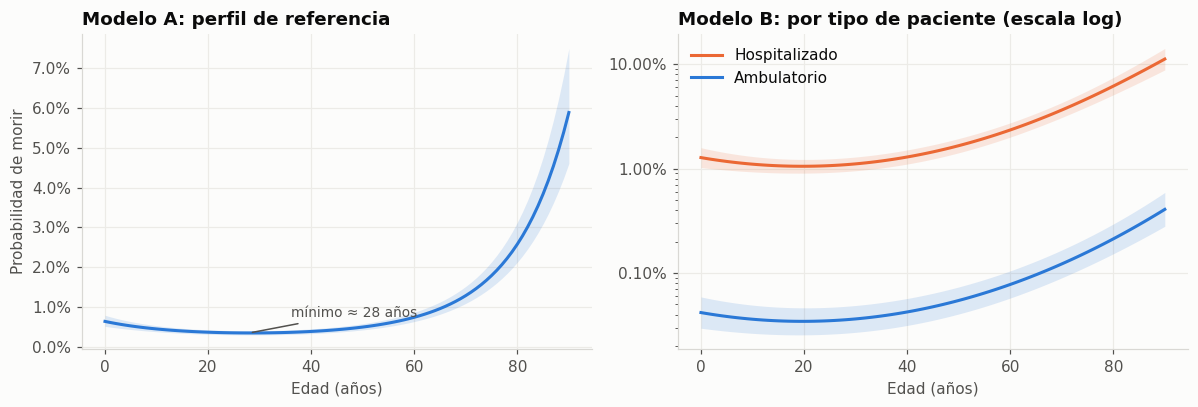

edad,0,5,18,30,50,70,85
Modelo A,0.64%,0.53%,0.38%,0.35%,0.50%,1.29%,3.84%
Modelo B ambulatorio,0.04%,0.04%,0.03%,0.04%,0.05%,0.12%,0.29%
Modelo B hospitalizado,1.28%,1.17%,1.06%,1.11%,1.66%,3.65%,8.27%


In [8]:
def predecir_con_ic(m, datos):
    X = build_design_matrices([m.model.data.design_info], datos, return_type="dataframe")[0]
    eta = X.values @ m.params.values
    ee = np.sqrt(np.einsum("ij,jk,ik->i", X.values, m.cov_params().values, X.values))
    expit = lambda z: 1 / (1 + np.exp(-z))
    return expit(eta), expit(eta - 1.96 * ee), expit(eta + 1.96 * ee)

edades = np.arange(0, 91)
perfil = pd.DataFrame({v: 0 for v in VARIABLES_B}, index=edades).assign(SIN_SEROTIPO=1)
perfil["EDAD10"] = (edades - 30) / 10
perfil["EDAD10_2"] = perfil.EDAD10 ** 2

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
p, lo, hi = predecir_con_ic(modelo_a, perfil)
axes[0].fill_between(edades, lo, hi, color=AZUL, alpha=0.15, linewidth=0)
axes[0].plot(edades, p, color=AZUL, linewidth=2)
axes[0].set(title="Modelo A: perfil de referencia", xlabel="Edad (años)", ylabel="Probabilidad de morir")
edad_min = edades[np.argmin(p)]
axes[0].annotate(f"mínimo ≈ {edad_min} años", xy=(edad_min, p.min()), xytext=(edad_min + 8, p.min() + 0.004),
                 arrowprops=dict(arrowstyle="-", color=TINTA_2), fontsize=9, color=TINTA_2)

for h, color, etiqueta in [(1, NARANJA, "Hospitalizado"), (0, AZUL, "Ambulatorio")]:
    p, lo, hi = predecir_con_ic(modelo_b, perfil.assign(HOSPITALIZADO=h))
    axes[1].fill_between(edades, lo, hi, color=color, alpha=0.15, linewidth=0)
    axes[1].plot(edades, p, color=color, linewidth=2, label=etiqueta)
axes[1].set_yscale("log")
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=2))
axes[1].set(title="Modelo B: por tipo de paciente (escala log)", xlabel="Edad (años)")
axes[1].legend(loc="upper left")
axes[0].yaxis.set_major_formatter(pct)
plt.tight_layout(); plt.show()

ref = perfil.loc[[0, 5, 18, 30, 50, 70, 85]]
pd.DataFrame({"Modelo A": predecir_con_ic(modelo_a, ref)[0],
              "Modelo B ambulatorio": predecir_con_ic(modelo_b, ref.assign(HOSPITALIZADO=0))[0],
              "Modelo B hospitalizado": predecir_con_ic(modelo_b, ref.assign(HOSPITALIZADO=1))[0]},
             index=pd.Index(ref.index, name="edad")).T.map("{:.2%}".format)

## 6 · Desempeño en el conjunto de prueba

Métricas sobre datos **no usados para ajustar**:

- **AUC-ROC**: probabilidad de que un fallecido elegido al azar reciba mayor riesgo predicho que un sobreviviente al azar (0.5 = azar, 1 = perfecto). IC 95% por bootstrap.
- **AUC-PR** (precisión promedio): más exigente con clases raras; su valor de referencia (azar) es la prevalencia, ≈ 0.7%.
- **Brier**: error cuadrático medio de la probabilidad; se compara con el de predecir siempre la prevalencia.

In [9]:
y_prueba = prueba.DEFUNCION.values
pred = {"Modelo A": modelo_a.predict(prueba).values, "Modelo B": modelo_b.predict(prueba).values}
COLORES = {"Modelo A": AZUL, "Modelo B": NARANJA}

def auc_bootstrap(y, p, n=500, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    aucs = [roc_auc_score(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return np.percentile(aucs, [2.5, 97.5])

brier_ref = brier_score_loss(y_prueba, np.full(len(y_prueba), entrena.DEFUNCION.mean()))
filas = []
for nombre, p in pred.items():
    lo, hi = auc_bootstrap(y_prueba, p)
    filas.append({"modelo": nombre, "AUC-ROC": roc_auc_score(y_prueba, p), "IC 95%": f"{lo:.3f} – {hi:.3f}",
                  "AUC-PR": average_precision_score(y_prueba, p), "AUC-PR / prevalencia": average_precision_score(y_prueba, p) / y_prueba.mean(),
                  "Brier": brier_score_loss(y_prueba, p), "Brier sin modelo": brier_ref})
desempeno = pd.DataFrame(filas).set_index("modelo")
desempeno.style.format({"AUC-ROC": "{:.3f}", "AUC-PR": "{:.3f}", "AUC-PR / prevalencia": "{:.1f}×",
                        "Brier": "{:.5f}", "Brier sin modelo": "{:.5f}"})

,AUC-ROC,IC 95%,AUC-PR,AUC-PR / prevalencia,Brier,Brier sin modelo
modelo,,,,,,
Modelo A,0.694,0.670 – 0.720,0.035,5.0×,0.00689,0.00695
Modelo B,0.861,0.848 – 0.872,0.057,8.1×,0.00678,0.00695


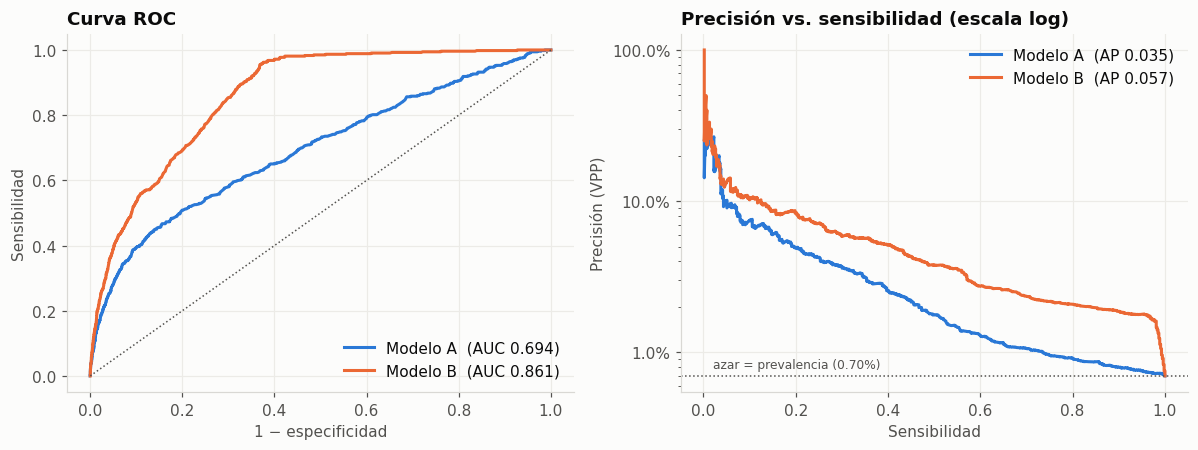

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for nombre, p in pred.items():
    fpr, tpr, _ = roc_curve(y_prueba, p)
    axes[0].plot(fpr, tpr, color=COLORES[nombre], linewidth=2, label=f"{nombre}  (AUC {desempeno.loc[nombre, 'AUC-ROC']:.3f})")
    prec, sens, _ = precision_recall_curve(y_prueba, p)
    axes[1].plot(sens[sens > 0], prec[sens > 0], color=COLORES[nombre], linewidth=2, label=f"{nombre}  (AP {desempeno.loc[nombre, 'AUC-PR']:.3f})")
axes[0].plot([0, 1], [0, 1], color=TINTA_2, linestyle=":", linewidth=1)
axes[0].set(title="Curva ROC", xlabel="1 − especificidad", ylabel="Sensibilidad")
axes[1].axhline(y_prueba.mean(), color=TINTA_2, linestyle=":", linewidth=1)
axes[1].text(0.02, y_prueba.mean() * 1.08, "azar = prevalencia (0.70%)", ha="left", va="bottom", fontsize=8, color=TINTA_2)
axes[1].set_yscale("log")
axes[1].yaxis.set_major_formatter(pct)
axes[1].set(title="Precisión vs. sensibilidad (escala log)", xlabel="Sensibilidad", ylabel="Precisión (VPP)")
for ax in axes: ax.legend(loc="lower right" if ax is axes[0] else "upper right")
plt.tight_layout(); plt.show()

## 7 · Calibración

Un modelo está **calibrado** si, entre los pacientes a los que predice 2% de riesgo, muere ≈ 2%. Se agrupan los pacientes de prueba en **deciles de riesgo predicho** y se compara la mortalidad predicha con la observada.

La prueba de **Hosmer-Lemeshow** ($H_0$: el modelo está bien calibrado) se reporta, pero con decenas de miles de observaciones detecta diferencias minúsculas, así que pesa más la gráfica.

Modelo A: Hosmer-Lemeshow = 8.4 (gl = 8, p = 0.394) | muertes esperadas = 530, observadas = 529
Modelo B: Hosmer-Lemeshow = 12.1 (gl = 8, p = 0.148) | muertes esperadas = 525, observadas = 529


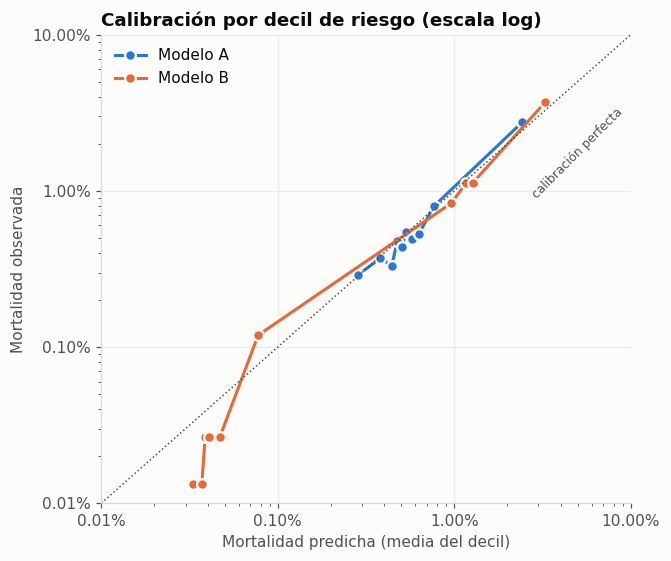

In [11]:
def calibracion(y, p, grupos=10):
    df = pd.DataFrame({"y": y, "p": p})
    df["decil"] = pd.qcut(df.p.rank(method="first"), grupos, labels=False)
    t = df.groupby("decil").agg(n=("y", "size"), observadas=("y", "sum"), esperadas=("p", "sum"), p_media=("p", "mean"))
    t["mort_obs"] = t.observadas / t.n
    hl = (((t.observadas - t.esperadas) ** 2) / (t.esperadas * (1 - t.esperadas / t.n))).sum()
    return t, hl, stats.chi2.sf(hl, grupos - 2)

fig, ax = plt.subplots(figsize=(6.2, 5.2))
tablas_cal = {}
for nombre, p in pred.items():
    t, hl, p_hl = calibracion(y_prueba, p)
    tablas_cal[nombre] = t
    print(f"{nombre}: Hosmer-Lemeshow = {hl:.1f} (gl = 8, p = {p_hl:.3f}) | "
          f"muertes esperadas = {p.sum():.0f}, observadas = {y_prueba.sum()}")
    ax.plot(t.p_media, t.mort_obs, "o-", color=COLORES[nombre], linewidth=2, markersize=7,
            markeredgecolor="#fcfcfb", markeredgewidth=1.5, label=nombre)
lim = [1e-4, 0.1]
ax.plot(lim, lim, color=TINTA_2, linestyle=":", linewidth=1)
ax.text(0.05, 0.05 * 0.7, "calibración perfecta", rotation=45, fontsize=8, color=TINTA_2, ha="center", va="top")
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, title="Calibración por decil de riesgo (escala log)",
       xlabel="Mortalidad predicha (media del decil)", ylabel="Mortalidad observada")
for eje in (ax.xaxis, ax.yaxis): eje.set_major_formatter(mticker.PercentFormatter(1, decimals=2))
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

In [12]:
# Detalle de calibración del modelo B por decil
t = tablas_cal["Modelo B"]
t.assign(p_media=t.p_media.map("{:.3%}".format), mort_obs=t.mort_obs.map("{:.3%}".format),
         esperadas=t.esperadas.round(1)).rename(columns={"p_media": "predicha", "mort_obs": "observada"})

,n,observadas,esperadas,predicha,observada
decil,,,,,
0,7557,1,2.5,0.033%,0.013%
1,7557,1,2.8,0.037%,0.013%
2,7557,2,2.9,0.039%,0.026%
3,7557,2,3.1,0.041%,0.026%
4,7557,2,3.5,0.047%,0.026%
5,7557,9,5.8,0.077%,0.119%
6,7557,63,72.7,0.962%,0.834%
7,7557,85,88.3,1.169%,1.125%
8,7557,85,96.2,1.273%,1.125%


## 8 · Umbral de clasificación

Para convertir la probabilidad en una alerta ("paciente de alto riesgo") hay que elegir un umbral. Con 0.7% de prevalencia, el umbral de 0.5 no clasificaría a casi nadie como positivo. Se comparan dos criterios, elegidos en **entrenamiento** y evaluados en **prueba**:

- **Youden**: maximiza sensibilidad + especificidad − 1.
- **Sensibilidad ≥ 90%**: prioriza no dejar pasar fallecidos (tamizaje), aceptando más falsos positivos.

In [13]:
def umbrales(m):
    y, p = entrena.DEFUNCION.values, m.predict(entrena).values
    fpr, tpr, u = roc_curve(y, p)
    return {"Youden": u[np.argmax(tpr - fpr)], "Sensibilidad ≥ 90%": u[np.argmax(tpr >= 0.90)]}

def metricas(y, p, u):
    tn, fp, fn, tp = confusion_matrix(y, p >= u).ravel()
    return {"umbral": u, "sensibilidad": tp / (tp + fn), "especificidad": tn / (tn + fp),
            "VPP": tp / (tp + fp), "VPN": tn / (tn + fn), "% marcados como alto riesgo": (tp + fp) / len(y),
            "VP": tp, "FN": fn, "FP": fp, "VN": tn}

filas = []
for nombre, m in [("Modelo A", modelo_a), ("Modelo B", modelo_b)]:
    for criterio, u in umbrales(m).items():
        filas.append({"modelo": nombre, "criterio": criterio, **metricas(y_prueba, pred[nombre], u)})
tabla_umbral = pd.DataFrame(filas).set_index(["modelo", "criterio"])
tabla_umbral.style.format({"umbral": "{:.4f}", "sensibilidad": "{:.1%}", "especificidad": "{:.1%}", "VPP": "{:.2%}",
                           "VPN": "{:.3%}", "% marcados como alto riesgo": "{:.1%}",
                           "VP": "{:,}", "FN": "{:,}", "FP": "{:,}", "VN": "{:,}"})

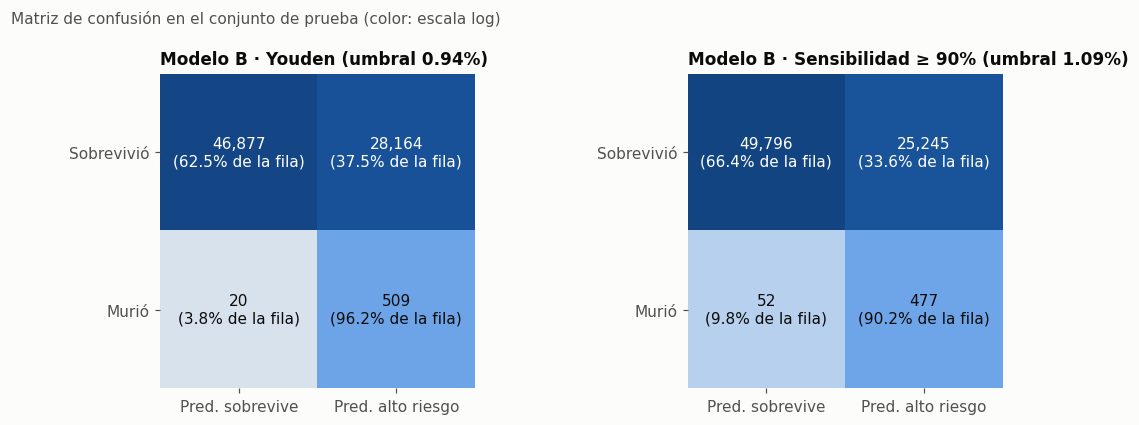

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
for ax, criterio in zip(axes, ["Youden", "Sensibilidad ≥ 90%"]):
    f = tabla_umbral.loc[("Modelo B", criterio)]
    matriz = np.array([[f.VN, f.FP], [f.FN, f.VP]]).astype(int)
    ax.imshow(np.log10(matriz), cmap=SECUENCIAL, vmin=1, vmax=5)
    for (i, j), v in np.ndenumerate(matriz):
        fila_total = matriz[i].sum()
        ax.text(j, i, f"{v:,}\n({v / fila_total:.1%} de la fila)", ha="center", va="center",
                color="white" if v > 5000 else TINTA, fontsize=10)
    ax.set_xticks([0, 1], ["Pred. sobrevive", "Pred. alto riesgo"])
    ax.set_yticks([0, 1], ["Sobrevivió", "Murió"])
    ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_title(f"Modelo B · {criterio} (umbral {f.umbral:.2%})", fontsize=11)
fig.suptitle("Matriz de confusión en el conjunto de prueba (color: escala log)", x=0.01, ha="left", fontsize=10, color=TINTA_2)
plt.tight_layout(); plt.show()

## 9 · Interacciones (análisis de sensibilidad)

Se prueban, una por una sobre el modelo B, interacciones clínicamente plausibles. Con más de 170 mil observaciones, efectos pequeños pueden salir significativos; solo se justificaría agregarlas si además mejoran el desempeño en prueba.

In [15]:
INTERACCIONES = {
    "Edad × hospitalizado": "HOSPITALIZADO:EDAD10",
    "Edad × hombre": "HOMBRE:EDAD10",
    "Diabetes × hipertensión": "DIABETES:HIPERTENSION",
    "Hemorrágicos × hospitalizado": "HEMORRAGICOS:HOSPITALIZADO",
}
filas = []
for nombre, termino in INTERACCIONES.items():
    m = ajustar(formula(VARIABLES_B, [termino]))
    lr, gl, p = prueba_lr(modelo_b, m)
    filas.append({"interacción": nombre, "OR de la interacción": np.exp(m.params[termino]), "LR": lr, "p": p,
                  "ΔAIC": m.aic - modelo_b.aic,
                  "ΔAUC en prueba": roc_auc_score(y_prueba, m.predict(prueba)) - desempeno.loc["Modelo B", "AUC-ROC"]})
pd.DataFrame(filas).set_index("interacción").style.format(
    {"OR de la interacción": "{:.2f}", "LR": "{:.1f}", "p": "{:.4f}", "ΔAIC": "{:+.1f}", "ΔAUC en prueba": "{:+.4f}"})

,OR de la interacción,LR,p,ΔAIC,ΔAUC en prueba
interacción,,,,,
Edad × hospitalizado,0.91,2.2,0.1377,-0.2,+0.0003
Edad × hombre,1.09,12.2,0.0005,-10.2,+0.0017
Diabetes × hipertensión,0.50,10.1,0.0015,-8.1,-0.0003
Hemorrágicos × hospitalizado,0.45,1.4,0.2413,+0.6,+0.0006


## 10 · Conclusiones

**Especificación.** Regresión logística con datos demográficos, hemorragia, comorbilidades, serotipo y edad **cuadrática** (centrada en 30 años). La edad cuadrática mejora claramente a la lineal (LR = 188, p ≈ 1e-42; ΔAIC = −186) y un spline no aporta más. El **mes se descartó** (LR = 16 con 11 gl, p = 0.14; empeora el AIC). Todos los modelos convergieron, incluidas las categorías con pocas muertes, aunque con IC amplios.

**Modelo A: factores de riesgo del paciente (sin hospitalización).** OR ajustadas significativas:

| Factor | OR (IC 95%) |
|---|---|
| Enfermedad renal | 5.7 (4.1 – 8.0) |
| Cirrosis hepática | 4.3 (2.0 – 9.6) |
| Hemorrágicos | 2.5 (1.9 – 3.4) |
| Inmunosupresión | 2.5 (1.3 – 4.8) |
| Diabetes | 2.1 (1.7 – 2.7) |
| Serotipo distinto de DENV1 | ≈ 1.9 – 2.3 |
| Embarazo | 1.9 (1.4 – 2.6) |
| Hipertensión | 1.5 (1.2 – 1.9) |
| Estado costero | 1.35 (1.2 – 1.5) |

Sexo e indígena no son significativos. Con la edad, el riesgo tiene forma de **J**: mínimo alrededor de los 28 años (≈ 0.35% en el perfil de referencia), algo mayor en recién nacidos (≈ 0.6%) y creciente a partir de los 50 (≈ 1.3% a los 70, ≈ 3.8% a los 85).

**Modelo B: con hospitalización.** La hospitalización domina (OR ≈ 31, IC 23 – 41) y, al incluirla, las OR de las demás variables se acercan a 1. **Siguen siendo significativas** enfermedad renal (4.0), cirrosis (3.2), inmunosupresión (2.1), hemorrágicos (2.0), diabetes (1.6) y la edad. **Dejan de serlo** hipertensión, embarazo, estado costero y serotipo: su efecto en el modelo A pasaba, al menos en parte, por que esos pacientes se hospitalizan más. Como la hospitalización es una consecuencia de la gravedad, para hablar de **factores de riesgo** conviene reportar el modelo A, y para **predecir** el desenlace de un paciente ya atendido, el modelo B.

**Desempeño en prueba (75,570 casos, 529 muertes).**

| | AUC-ROC (IC 95%) | AUC-PR | Hosmer-Lemeshow |
|---|---|---|---|
| Modelo A | 0.69 (0.67 – 0.72) | 0.035 (5× el azar) | p = 0.39 |
| Modelo B | 0.86 (0.85 – 0.87) | 0.057 (8× el azar) | p = 0.15 |

Los dos modelos están **bien calibrados**: predicen ≈ 525–530 muertes contra 529 observadas, y Hosmer-Lemeshow no rechaza. El modelo B sobreestima ligeramente el riesgo en los deciles más bajos (≈ 0.04% predicho vs. ≈ 0.02% observado), una diferencia irrelevante en términos absolutos. La discriminación del modelo A es **modesta**: con lo que se sabe del paciente antes de la atención se ordena el riesgo mejor que al azar, pero lejos de la perfección.

**Umbral.** Con un evento tan raro, la **precisión (VPP) es baja con cualquier umbral**: aun en el mejor caso, menos de 2 de cada 100 pacientes marcados como de alto riesgo muere. En cambio, el **VPN es muy alto** (> 99.9% en el modelo B). El modelo sirve más para **descartar** (identificar a quienes casi seguro sobreviven) que para confirmar.

Con el criterio de Youden, el modelo B marca al 38% de los pacientes y captura el **96% de las muertes**. Ese umbral prácticamente separa hospitalizados de ambulatorios, lo que confirma que la hospitalización hace casi todo el trabajo predictivo. El criterio de sensibilidad ≥ 90% da un umbral ligeramente más alto y marca al 34%.

**Interacciones.** Edad × hombre y diabetes × hipertensión salen significativas (p < 0.01), pero mejoran el AUC en prueba en menos de 0.002. Edad × hospitalización y hemorrágicos × hospitalización no son significativas. Por parsimonia **no se incluyen** en el modelo final.

**Limitaciones.**
- Los datos son de vigilancia epidemiológica: puede haber subregistro de comorbilidades y de defunciones.
- El serotipo está confundido con la época de captura.
- No hay variables clínicas de gravedad (signos de alarma, laboratorio), que probablemente explican buena parte de la mortalidad que el modelo A no capta.
- La asociación no implica causalidad.